## TASK-11

## Section 1 — Data acquisition

In [9]:

import numpy as np
from sklearn.datasets import fetch_openml

# Acquire Fashion-MNIST dataset
data = fetch_openml(
    "Fashion-MNIST",
    version=1,
    as_frame=False
)

X = data.data.astype(np.float32)
y = data.target.astype(np.int64)

# Standard train-test split
X_train = X[:60000]
y_train = y[:60000]

X_test = X[60000:]
y_test = y[60000:]

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Image features:", X.shape[1])


Dataset shape: (70000, 784)
Number of classes: 10
Training samples: 60000
Testing samples: 10000
Image features: 784


## Section 2 — Data preprocessing

In [10]:

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# X_train, y_train, X_test, y_test
# are loaded in Section 1.

preprocessing_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("pca", PCA(
        n_components=50,
        random_state=42
    ))
])

# Fit transformations using training data only
X_train_features = preprocessing_pipeline.fit_transform(X_train)

# Apply the same transformations to test data
X_test_features = preprocessing_pipeline.transform(X_test)

print("Before preprocessing:", X_train.shape)
print("After preprocessing:", X_train_features.shape)
print("Test features:", X_test_features.shape)
print(
    "Variance retained:",
    round(
        preprocessing_pipeline.named_steps["pca"]
        .explained_variance_ratio_.sum() * 100, 2
    ),
    "%"
)


Before preprocessing: (60000, 784)
After preprocessing: (60000, 50)
Test features: (10000, 50)
Variance retained: 86.25 %


## Section 3 — Exploratory data analysis and feature engineering

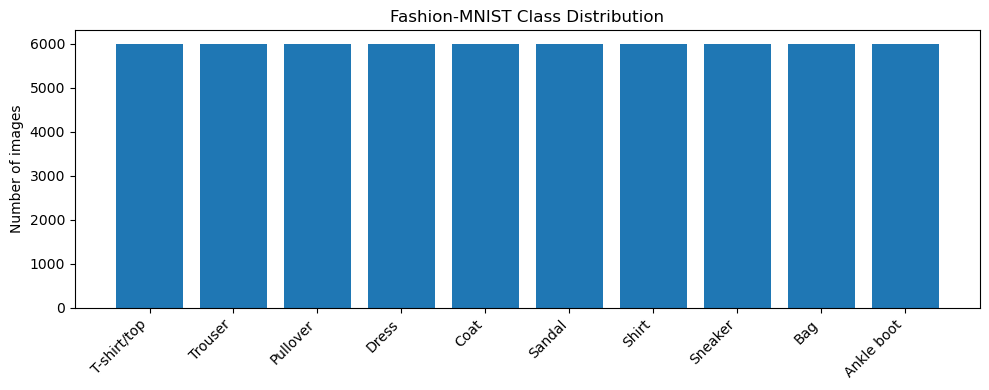

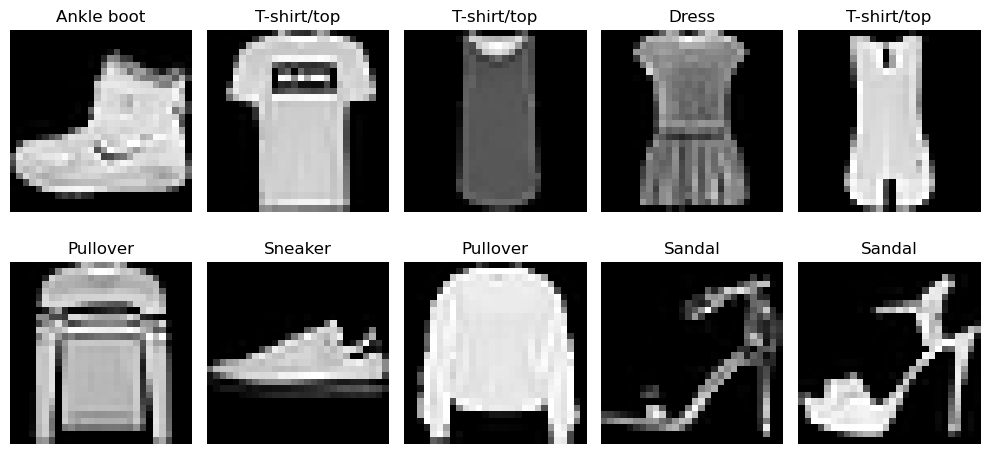

Original features: 784
Selected features: 50
Variance retained: 86.27 %


In [11]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from collections import Counter

labels = [
    "T-shirt/top", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Display class distribution
counts = Counter(y_train)

plt.figure(figsize=(10, 4))
plt.bar(
    [labels[i] for i in range(10)],
    [counts[i] for i in range(10)]
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("Fashion-MNIST Class Distribution")
plt.tight_layout()
plt.show()

# Display sample images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(labels[y_train[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

# Feature engineering using PCA
pca = PCA(n_components=50, random_state=42)
X_train_features = pca.fit_transform(
    X_train / 255.0
)

print("Original features:", X_train.shape[1])
print("Selected features:", X_train_features.shape[1])
print(
    "Variance retained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


## Section 4 — Model training

In [12]:

import time
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        C=10, max_iter=1000
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=9,
        weights="distance",
        n_jobs=-1
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
training_results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("scaler", MinMaxScaler()),
        ("pca", PCA(n_components=50, random_state=42)),
        ("classifier", classifier)
    ])

    start = time.time()
    pipeline.fit(X_train, y_train)
    elapsed = time.time() - start

    trained_models[name] = pipeline

    training_results.append({
        "Model": name,
        "Training Time (seconds)": round(elapsed, 2)
    })

    print(name, "trained successfully")

print(pd.DataFrame(training_results))


Logistic Regression trained successfully
KNN trained successfully
Random Forest trained successfully
                 Model  Training Time (seconds)
0  Logistic Regression                    10.93
1                  KNN                     0.62
2        Random Forest                    14.67


## Section 5 — Model evaluation


Model: Logistic Regression
              precision    recall  f1-score   support

           0       0.79      0.81      0.80      1000
           1       0.97      0.95      0.96      1000
           2       0.72      0.70      0.71      1000
           3       0.82      0.85      0.83      1000
           4       0.71      0.73      0.72      1000
           5       0.94      0.92      0.93      1000
           6       0.56      0.54      0.55      1000
           7       0.90      0.92      0.91      1000
           8       0.93      0.93      0.93      1000
           9       0.94      0.94      0.94      1000

    accuracy                           0.83     10000
   macro avg       0.83      0.83      0.83     10000
weighted avg       0.83      0.83      0.83     10000


Model: KNN
              precision    recall  f1-score   support

           0       0.79      0.82      0.80      1000
           1       0.99      0.96      0.98      1000
           2       0.77      0.77     

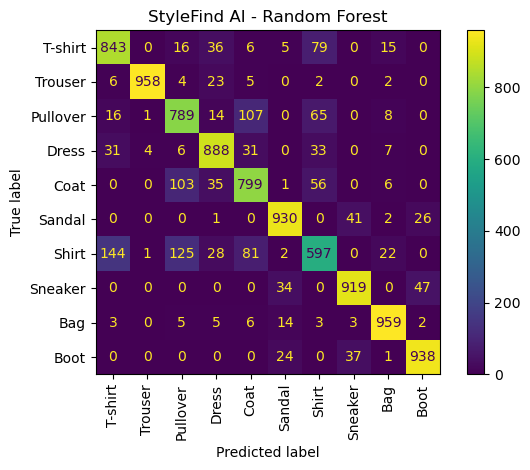


MODEL EVALUATION RESULTS
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.8288   0.828045  0.8288  0.828261
                KNN    0.8591   0.859758  0.8591  0.858946
      Random Forest    0.8620   0.860808  0.8620  0.860702


In [13]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
    classification_report
)

results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, predictions, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, average="macro", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\nModel:", name)
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

    if name == "Random Forest":
        ConfusionMatrixDisplay.from_predictions(
            y_test,
            predictions,
            display_labels=[
                "T-shirt", "Trouser", "Pullover", "Dress",
                "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Boot"
            ],
            xticks_rotation="vertical"
        )
        plt.title("StyleFind AI - Random Forest")
        plt.tight_layout()
        plt.show()

results_df = pd.DataFrame(results)
print("\nMODEL EVALUATION RESULTS")
print(results_df.to_string(index=False))

results_df.to_csv("model_evaluation.csv", index=False)


## Section 6 — Hyperparameter optimization

In [14]:

import joblib
import os

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Build complete preprocessing and classification pipeline
pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("pca", PCA(n_components=50, random_state=42)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

parameters = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 20]
}

search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameters,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Tune on a stratified subset for faster experimentation
from sklearn.model_selection import train_test_split

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=10000,
    stratify=y_train,
    random_state=42
)

search.fit(X_tune, y_tune)

print("Best parameters:", search.best_params_)
print("Best CV macro F1:", search.best_score_)

# Refit the best configuration on the full training dataset
best_model = search.best_estimator_
best_model.fit(X_train, y_train)

os.makedirs("models", exist_ok=True)
joblib.dump(
    best_model,
    "models/stylefind_best_model.joblib"
)

print("Optimized model saved successfully!")


Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'classifier__max_depth': 20, 'classifier__n_estimators': 200}
Best CV macro F1: 0.8351308686348758
Optimized model saved successfully!


## Section 7 — Model persistence and deployment-ready prediction

In [15]:

import os
import joblib
import numpy as np

from PIL import Image

MODEL_PATH = "models/stylefind_best_model.joblib"

LABELS = [
    "T-shirt/top", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Load trained model
if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        "Model not found. Run Section 6 first."
    )

model = joblib.load(MODEL_PATH)
print("StyleFind AI model loaded successfully!")

def predict_style(image_path):
    # Load and preprocess the uploaded image
    image = Image.open(image_path).convert("L")
    image = image.resize((28, 28))

    pixels = np.asarray(
        image, dtype=np.float32
    ).reshape(1, -1)

    # The saved pipeline handles scaling and PCA
    prediction = int(model.predict(pixels)[0])
    probabilities = model.predict_proba(pixels)[0]
    confidence = float(np.max(probabilities)) * 100

    print("Predicted Style:", LABELS[prediction])
    print("Model Confidence:", round(confidence, 2), "%")

    return LABELS[prediction], confidence

# Example: replace with your image path
# predict_style("test_sneaker.png")


StyleFind AI model loaded successfully!
